# Students Performance — Data Visualization Project

*   Seyhak Horn
*   CLD 375



In [1]:
from google.colab import drive
drive.mount('/content/drive')
file_path = "/content/drive/MyDrive/Could_Ml_classwork/03. DE Class Activity/Students Performance.csv"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

df = pd.read_csv(file_path)
print(df.shape)
df.head()

(5000, 23)


,Student_ID,First_Name,Last_Name,Email,Gender,Age,Department,Attendance (%),Midterm_Score,Final_Score,...,Projects_Score,Total_Score,Grade,Study_Hours_per_Week,Extracurricular_Activities,Internet_Access_at_Home,Parent_Education_Level,Family_Income_Level,Stress_Level (1-10),Sleep_Hours_per_Night
0,S1000,Omar,Williams,student0@university.com,Female,22,Mathematics,97.36,40.61,59.61,...,62.84,59.8865,F,10.3,Yes,No,Master's,Medium,1,5.9
1,S1001,Maria,Brown,student1@university.com,Male,18,Business,97.71,57.27,74.00,...,98.23,81.9170,B,27.1,No,No,High School,Low,4,4.3
2,S1002,Ahmed,Jones,student2@university.com,Male,24,Engineering,99.52,41.84,63.85,...,91.22,67.7170,D,12.4,Yes,No,High School,Low,9,6.1
3,S1003,Omar,Williams,student3@university.com,Female,24,Engineering,90.38,45.65,44.44,...,55.48,51.6535,F,25.5,No,Yes,High School,Low,8,4.9
4,S1004,John,Smith,student4@university.com,Female,23,CS,59.41,53.13,61.77,...,87.43,71.4030,C,13.3,Yes,No,Master's,Medium,6,4.5


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  5000 non-null   object 
 1   First_Name                  5000 non-null   object 
 2   Last_Name                   5000 non-null   object 
 3   Email                       5000 non-null   object 
 4   Gender                      5000 non-null   object 
 5   Age                         5000 non-null   int64  
 6   Department                  5000 non-null   object 
 7   Attendance (%)              5000 non-null   float64
 8   Midterm_Score               5000 non-null   float64
 9   Final_Score                 5000 non-null   float64
 10  Assignments_Avg             5000 non-null   float64
 11  Quizzes_Avg                 5000 non-null   float64
 12  Participation_Score         5000 non-null   float64
 13  Projects_Score              5000 

## Task 1 — Missing value treatment


In [4]:
miss = df.isna().sum()
miss = miss[miss > 0].to_frame("missing")
miss["% of rows"] = (miss["missing"] / len(df) * 100).round(2)
miss

,missing,% of rows
Parent_Education_Level,1025,20.5


`Parent_Education_Level` is the only column with missing data: **1,025 rows (20.5%)**.

It is **categorical**, so mean/median imputation does not apply.

20.5% is too large a share to silently assign to the most common category, so `"Unknown"` is the safer default
here. The mode version is kept alongside it so either can be used.

In [5]:
df["Parent_Education_Level"] = df["Parent_Education_Level"].fillna("Unknown")

print("Remaining missing values:", df.isna().sum().sum())
df["Parent_Education_Level"].value_counts()

Remaining missing values: 0


,count
Parent_Education_Level,
Unknown,1025
Bachelor's,1020
PhD,1012
Master's,1000
High School,943


## Task 2 — Outlier treatment


In [6]:
num_cols = df.select_dtypes(include=np.number).columns.drop("Age")

rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append({"column": col, "lower_fence": round(lo, 2),
                 "upper_fence": round(hi, 2), "n_outliers": n})

outlier_report = pd.DataFrame(rows).sort_values("n_outliers", ascending=False)
outlier_report

,column,lower_fence,upper_fence,n_outliers
7,Total_Score,51.27,91.98,4
1,Midterm_Score,10.63,130.84,0
0,Attendance (%),25.57,125.24,0
2,Final_Score,10.86,127.76,0
3,Assignments_Avg,24.82,124.87,0
5,Participation_Score,-50.56,151.14,0
4,Quizzes_Avg,24.95,124.70,0
6,Projects_Score,23.48,126.12,0
8,Study_Hours_per_Week,-6.80,42.00,0
9,Stress_Level (1-10),-4.50,15.50,0


**Result: only `Total_Score` has outliers — 4 rows out of 5,000 (0.08%), all on the high side.**

Now inspect the 4 flagged rows before making any decisions.

In [7]:
q1, q3 = df["Total_Score"].quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr

flagged = df[(df["Total_Score"] < lo) | (df["Total_Score"] > hi)]
flagged[["Student_ID", "Total_Score", "Grade", "Midterm_Score",
         "Final_Score", "Assignments_Avg", "Projects_Score"]]

,Student_ID,Total_Score,Grade,Midterm_Score,Final_Score,Assignments_Avg,Projects_Score
1104,S2104,95.0915,A,95.92,99.55,85.02,95.45
1155,S2155,50.6020,F,43.78,40.36,50.42,52.04
2108,S3108,93.3160,A,99.42,95.73,97.89,85.93
4974,S5974,92.6520,A,93.50,97.85,88.55,93.03


**Decision: no treatment applied.**

These are valid high-performing "A" students with consistent component scores (all within 0–100), not data errors.


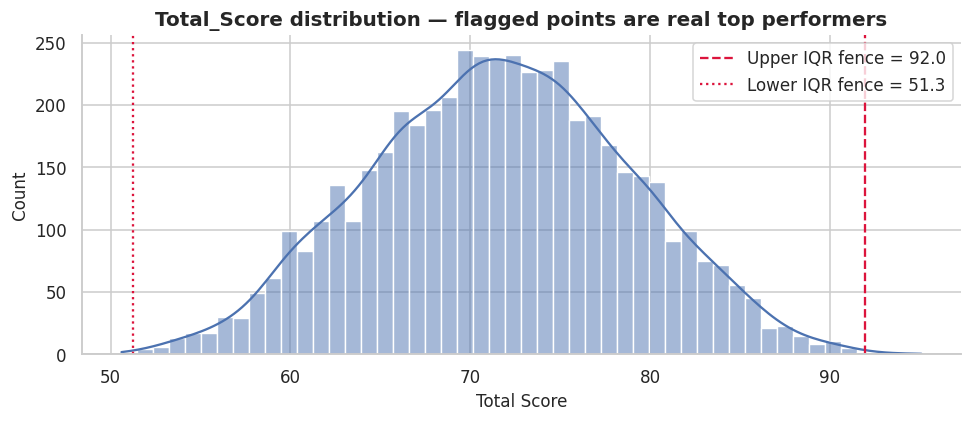

In [8]:
plt.figure(figsize=(9, 4))
sns.histplot(df["Total_Score"], bins=50, kde=True, color="#4C72B0")
plt.axvline(hi, color="crimson", ls="--", lw=1.5, label=f"Upper IQR fence = {hi:.1f}")
plt.axvline(lo, color="crimson", ls=":", lw=1.5, label=f"Lower IQR fence = {lo:.1f}")
plt.title("Total_Score distribution — flagged points are real top performers")
plt.xlabel("Total Score")
plt.legend()
plt.tight_layout()
plt.show()

## Task 3 — How many students received each grade?

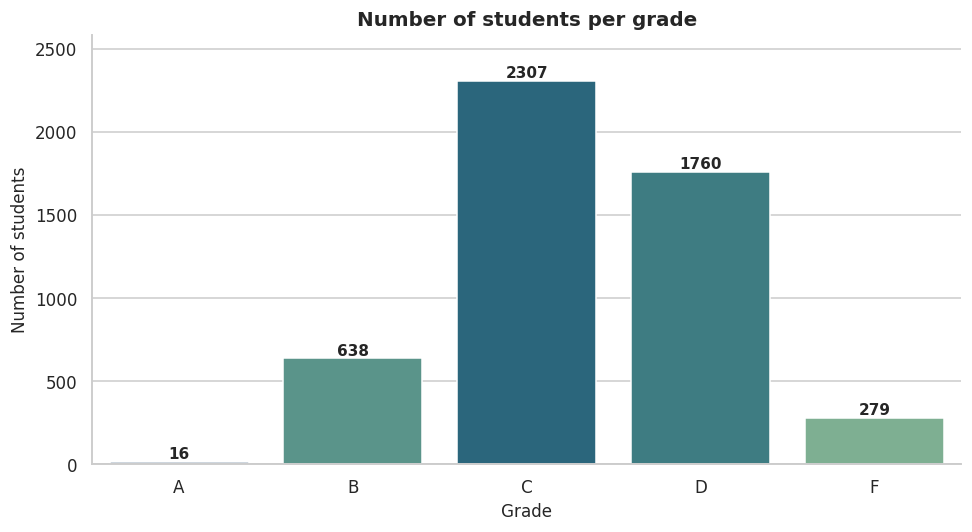

,students
Grade,
A,16
B,638
C,2307
D,1760
F,279


In [9]:
order = ["A", "B", "C", "D", "F"]
counts = df["Grade"].value_counts().reindex(order)

ax = sns.countplot(data=df, x="Grade", order=order, palette="crest", hue="Grade", legend=False)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_title("Number of students per grade")
ax.set_ylabel("Number of students")
ax.set_ylim(0, counts.max() * 1.12)
plt.tight_layout()
plt.show()

counts.to_frame("students")

## Task 4 — "There are more female students than male students." True or False?

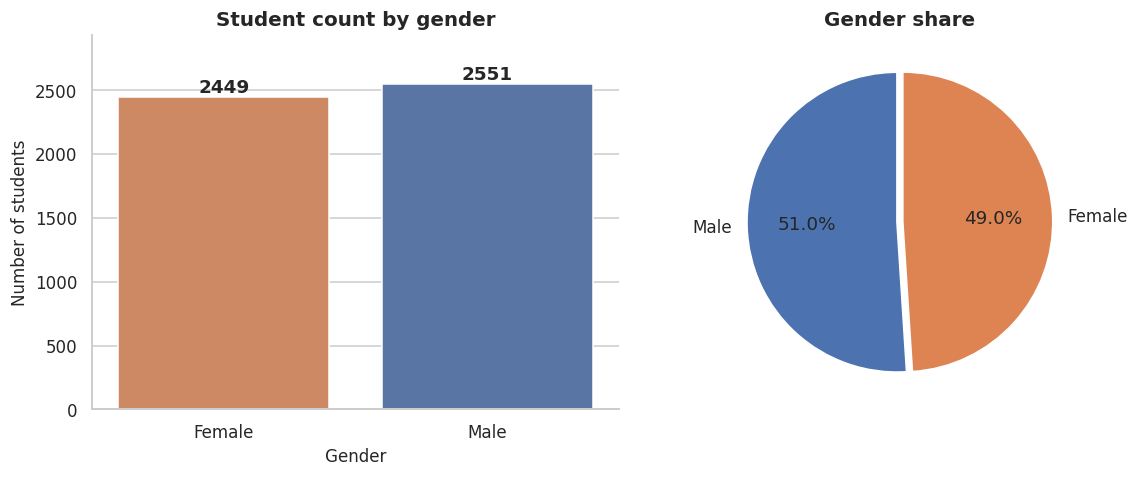

,students
Gender,
Male,2551
Female,2449


In [10]:
g = df["Gender"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ax = sns.countplot(data=df, x="Gender", ax=axes[0], palette=["#DD8452", "#4C72B0"],
                   hue="Gender", legend=False)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontweight="bold")
ax.set_title("Student count by gender")
ax.set_ylabel("Number of students")
ax.set_ylim(0, g.max() * 1.15)

axes[1].pie(g.values, labels=g.index, autopct="%1.1f%%", startangle=90,
            colors=["#4C72B0", "#DD8452"], explode=(0.02, 0.02))
axes[1].set_title("Gender share")

plt.tight_layout()
plt.show()

g.to_frame("students")

**Answer: FALSE.**

- Male: **2,551** (51.0%)
- Female: **2,449** (49.0%)


## Task 5 — Which income group has the most students?

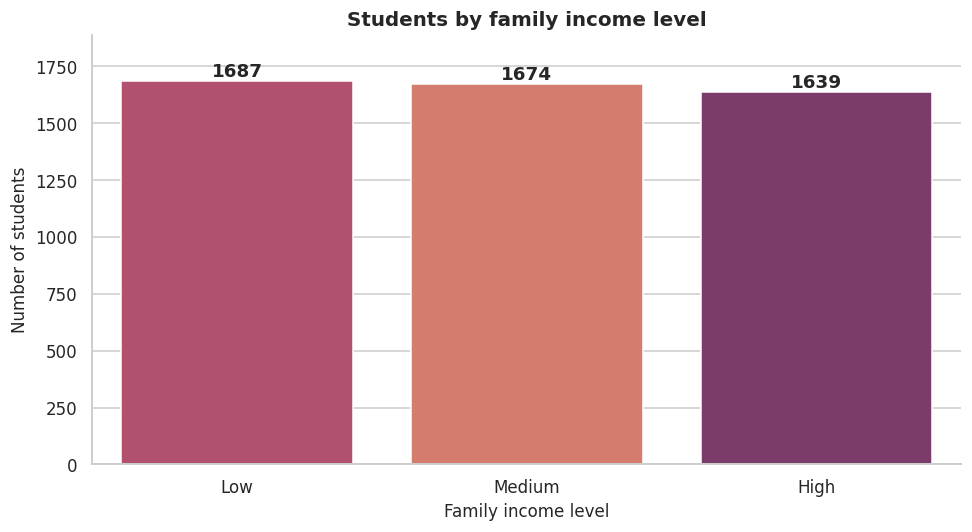

,students,pct
Family_Income_Level,,
Low,1687,33.7
Medium,1674,33.5
High,1639,32.8


In [11]:
inc_order = ["Low", "Medium", "High"]
inc = df["Family_Income_Level"].value_counts().reindex(inc_order)

ax = sns.countplot(data=df, x="Family_Income_Level", order=inc_order,
                   palette="flare", hue="Family_Income_Level", legend=False)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontweight="bold")
ax.set_title("Students by family income level")
ax.set_xlabel("Family income level")
ax.set_ylabel("Number of students")
ax.set_ylim(0, inc.max() * 1.12)
plt.tight_layout()
plt.show()

inc.to_frame("students").assign(pct=lambda d: (d["students"] / len(df) * 100).round(1))

**Answer: the Low income group, with 1,687 students (33.7%).**



## Task 6 — What is the study-hour pattern?

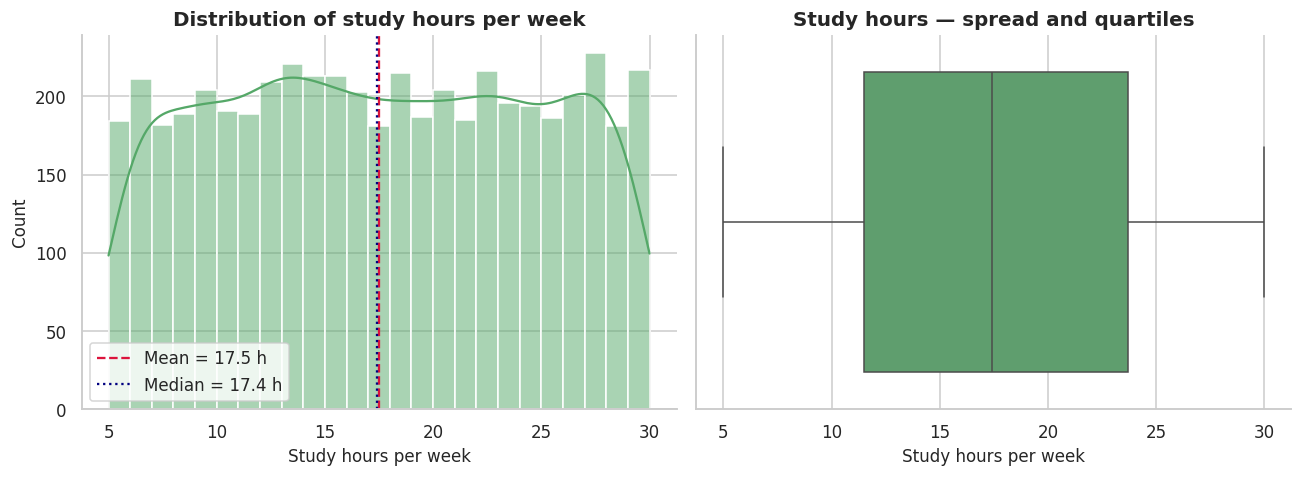

,Study_Hours_per_Week
count,5000.00
mean,17.52
std,7.19
min,5.00
25%,11.50
50%,17.40
75%,23.70
max,30.00


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(df["Study_Hours_per_Week"], bins=25, kde=True, color="#55A868", ax=axes[0])
axes[0].axvline(df["Study_Hours_per_Week"].mean(), color="crimson", ls="--",
                label=f"Mean = {df['Study_Hours_per_Week'].mean():.1f} h")
axes[0].axvline(df["Study_Hours_per_Week"].median(), color="navy", ls=":",
                label=f"Median = {df['Study_Hours_per_Week'].median():.1f} h")
axes[0].set_title("Distribution of study hours per week")
axes[0].set_xlabel("Study hours per week")
axes[0].legend()

sns.boxplot(x=df["Study_Hours_per_Week"], color="#55A868", ax=axes[1])
axes[1].set_title("Study hours — spread and quartiles")
axes[1].set_xlabel("Study hours per week")

plt.tight_layout()
plt.show()

df["Study_Hours_per_Week"].describe().round(2).to_frame("Study_Hours_per_Week")

**Answer: the pattern is essentially flat (uniform), not bell-shaped.**

- Range: 5.0 to 30.0 hours, with students spread evenly across the whole range
- Mean 17.5 h, median 17.5 h — mean ≈ median means no skew
- IQR: roughly 11.3 h to 23.7 h, i.e. the middle half of students study between ~11 and ~24 hours


## Task 7 — Grades split by gender

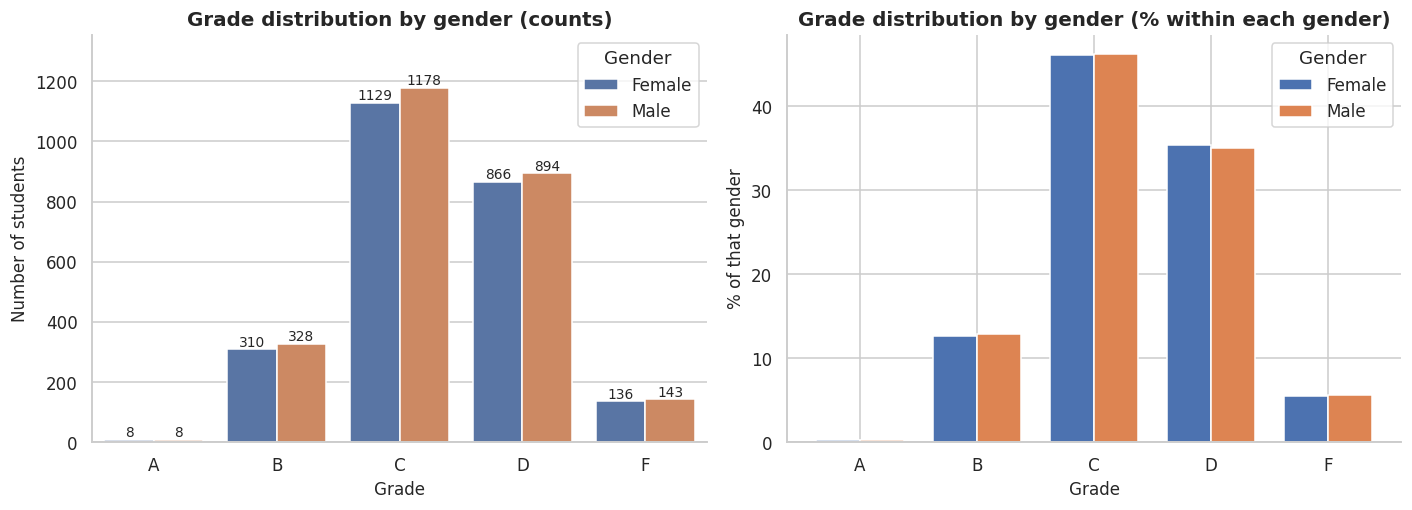

Gender,Female,Male
Grade,,
A,8,8
B,310,328
C,1129,1178
D,866,894
F,136,143


In [13]:
ct = pd.crosstab(df["Grade"], df["Gender"]).reindex(order)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ax = sns.countplot(data=df, x="Grade", hue="Gender", order=order,
                   palette=["#4C72B0", "#DD8452"], ax=axes[0])
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
ax.set_title("Grade distribution by gender (counts)")
ax.set_ylabel("Number of students")
ax.set_ylim(0, ct.values.max() * 1.15)

pct = ct.div(ct.sum(axis=0), axis=1) * 100
pct.plot(kind="bar", ax=axes[1], color=["#4C72B0", "#DD8452"], width=0.75)
axes[1].set_title("Grade distribution by gender (% within each gender)")
axes[1].set_ylabel("% of that gender")
axes[1].set_xlabel("Grade")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

ct

**Answer: grade C has the highest number of both men and women.**



## Task 8 — Study hours vs test score

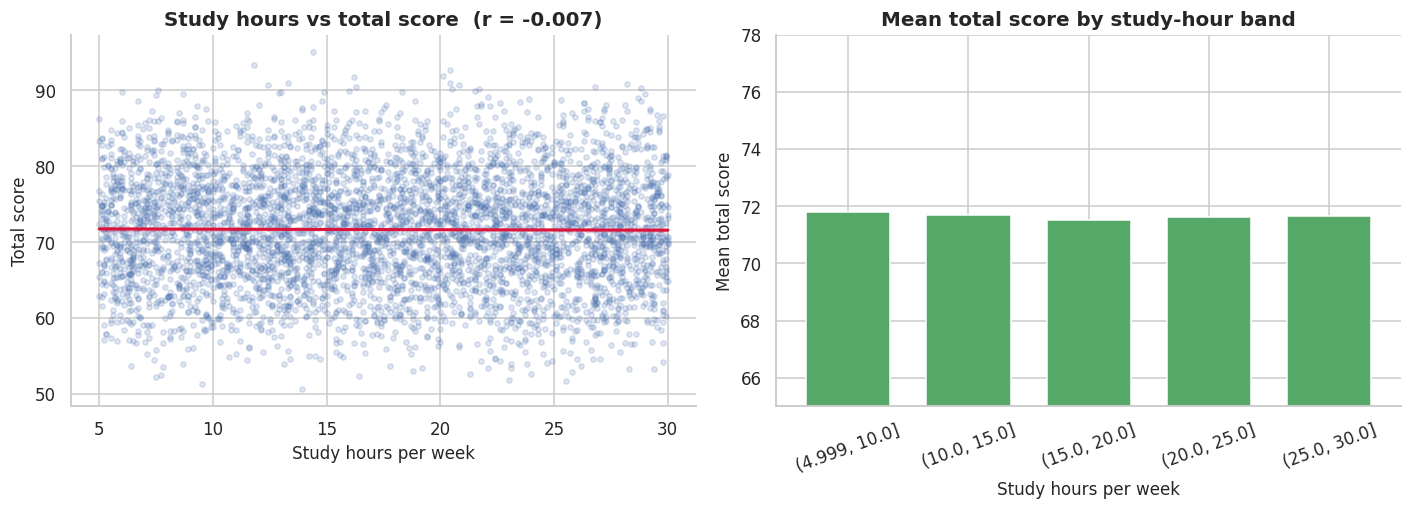

Pearson correlation: -0.0066


,mean_total_score
Study_Hours_per_Week,
"(4.999, 10.0]",71.78
"(10.0, 15.0]",71.69
"(15.0, 20.0]",71.52
"(20.0, 25.0]",71.61
"(25.0, 30.0]",71.65


In [14]:
r = df["Study_Hours_per_Week"].corr(df["Total_Score"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.regplot(data=df, x="Study_Hours_per_Week", y="Total_Score", ax=axes[0],
            scatter_kws={"alpha": 0.18, "s": 12, "color": "#4C72B0"},
            line_kws={"color": "crimson", "lw": 2})
axes[0].set_title(f"Study hours vs total score  (r = {r:.3f})")
axes[0].set_xlabel("Study hours per week")
axes[0].set_ylabel("Total score")

# Binned means make a weak trend visible if one exists
bins = pd.cut(df["Study_Hours_per_Week"], bins=[5, 10, 15, 20, 25, 30], include_lowest=True)
binned = df.groupby(bins, observed=True)["Total_Score"].mean()
binned.plot(kind="bar", ax=axes[1], color="#55A868", width=0.7)
axes[1].set_ylim(65, 78)
axes[1].set_title("Mean total score by study-hour band")
axes[1].set_xlabel("Study hours per week")
axes[1].set_ylabel("Mean total score")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

print(f"Pearson correlation: {r:.4f}")
binned.round(2).to_frame("mean_total_score")

**Answer: there is no relationship. r = -0.007, effectively zero.**


## Task 9 — Extracurricular activities vs test score

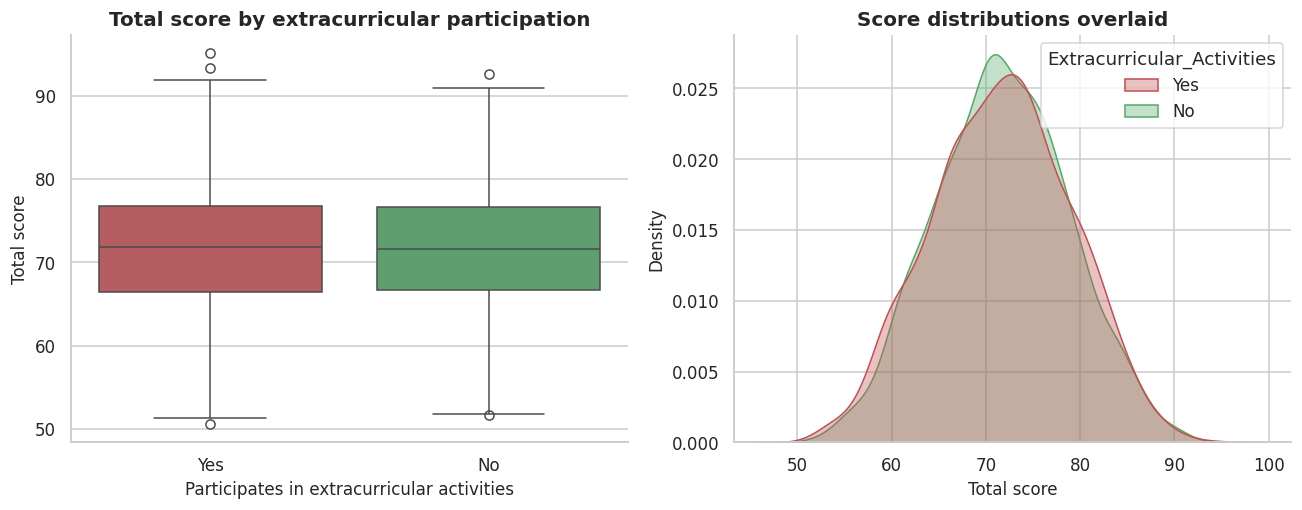

,count,mean,median,std
Extracurricular_Activities,,,,
No,2488,71.678,71.592,7.080
Yes,2512,71.626,71.778,7.377


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

sns.boxplot(data=df, x="Extracurricular_Activities", y="Total_Score",
            palette=["#C44E52", "#55A868"], hue="Extracurricular_Activities",
            legend=False, ax=axes[0])
axes[0].set_title("Total score by extracurricular participation")
axes[0].set_xlabel("Participates in extracurricular activities")
axes[0].set_ylabel("Total score")

sns.kdeplot(data=df, x="Total_Score", hue="Extracurricular_Activities",
            fill=True, alpha=0.35, palette=["#C44E52", "#55A868"], ax=axes[1])
axes[1].set_title("Score distributions overlaid")
axes[1].set_xlabel("Total score")

plt.tight_layout()
plt.show()

df.groupby("Extracurricular_Activities")["Total_Score"].agg(["count", "mean", "median", "std"]).round(3)

**Answer: no trend.**

- No: mean **71.68**, median 71.7
- Yes: mean **71.63**, median 71.6



## Task 10 — Attendance vs test score

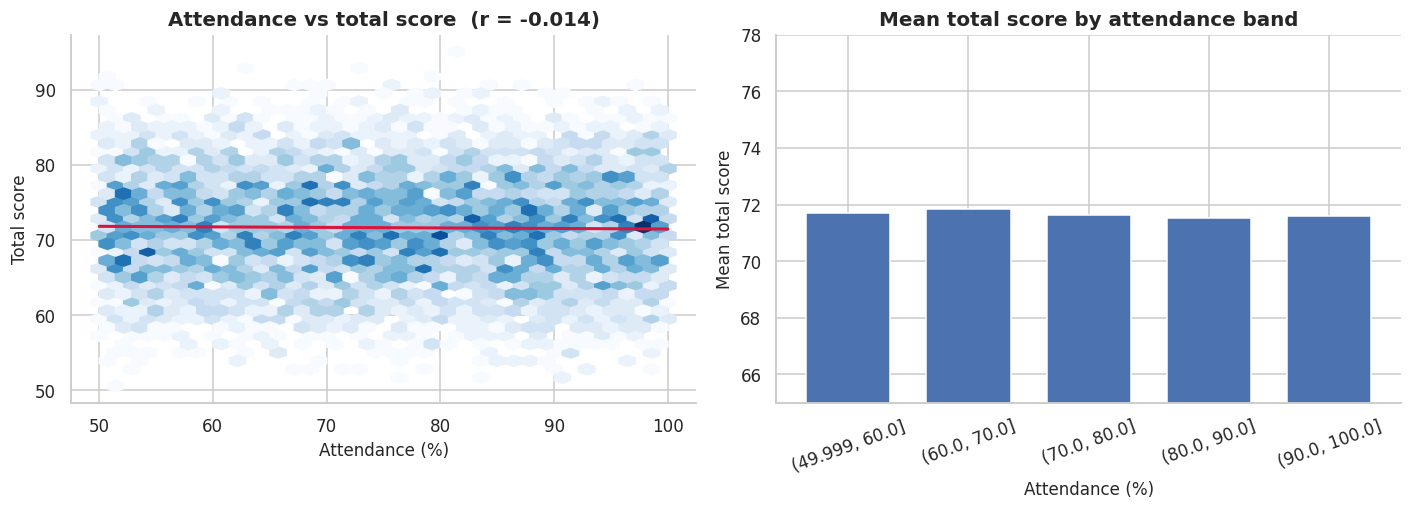

Pearson correlation: -0.0142


,mean_total_score
Attendance (%),
"(49.999, 60.0]",71.69
"(60.0, 70.0]",71.83
"(70.0, 80.0]",71.63
"(80.0, 90.0]",71.52
"(90.0, 100.0]",71.60


In [16]:
r_att = df["Attendance (%)"].corr(df["Total_Score"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].hexbin(df["Attendance (%)"], df["Total_Score"], gridsize=35, cmap="Blues", mincnt=1)
m, b = np.polyfit(df["Attendance (%)"], df["Total_Score"], 1)
xs = np.linspace(df["Attendance (%)"].min(), df["Attendance (%)"].max(), 100)
axes[0].plot(xs, m * xs + b, color="crimson", lw=2)
axes[0].set_title(f"Attendance vs total score  (r = {r_att:.3f})")
axes[0].set_xlabel("Attendance (%)")
axes[0].set_ylabel("Total score")

att_bins = pd.cut(df["Attendance (%)"], bins=[50, 60, 70, 80, 90, 100], include_lowest=True)
att_binned = df.groupby(att_bins, observed=True)["Total_Score"].mean()
att_binned.plot(kind="bar", ax=axes[1], color="#4C72B0", width=0.7)
axes[1].set_ylim(65, 78)
axes[1].set_title("Mean total score by attendance band")
axes[1].set_xlabel("Attendance (%)")
axes[1].set_ylabel("Mean total score")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

print(f"Pearson correlation: {r_att:.4f}")
att_binned.round(2).to_frame("mean_total_score")

**Answer: no pattern. r = -0.014.**


## Task 11 — "If stress level is lower, more students get a good score." True or False?

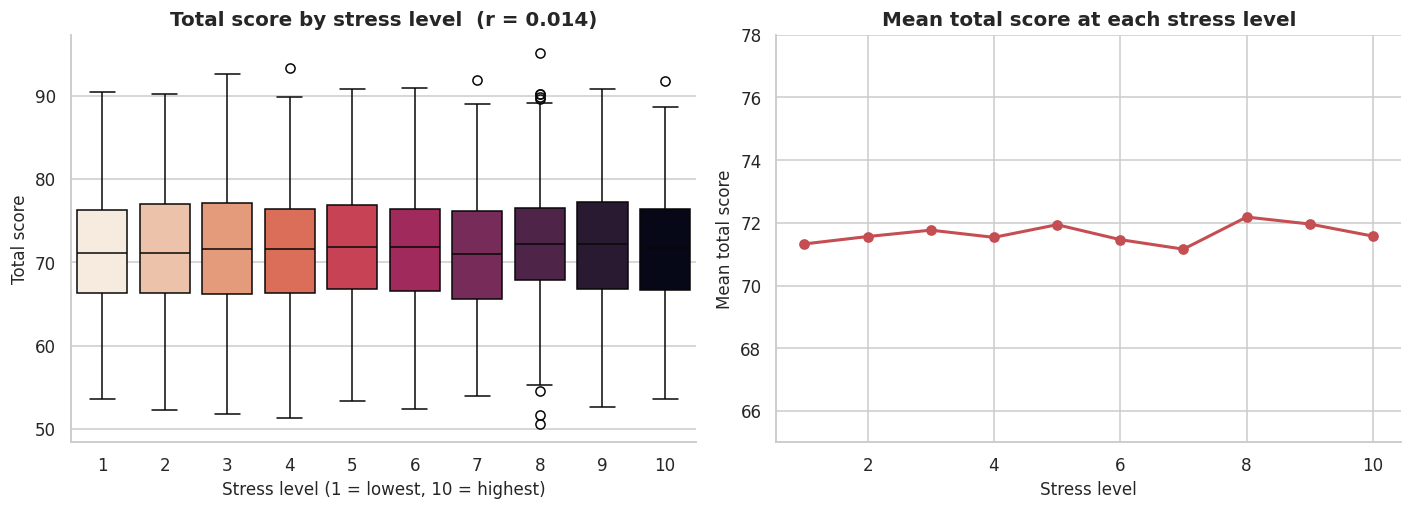

,mean_score,n_students,n_scoring_80+,% scoring 80+
Stress_Level (1-10),,,,
1,71.33,521,62,11.9
2,71.56,498,64,12.9
3,71.77,479,68,14.2
4,71.54,481,69,14.3
5,71.94,519,75,14.5
6,71.47,479,56,11.7
7,71.16,502,62,12.4
8,72.19,515,61,11.8
9,71.96,505,71,14.1


In [17]:
r_st = df["Stress_Level (1-10)"].corr(df["Total_Score"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.boxplot(data=df, x="Stress_Level (1-10)", y="Total_Score",
            palette="rocket_r", hue="Stress_Level (1-10)", legend=False, ax=axes[0])
axes[0].set_title(f"Total score by stress level  (r = {r_st:.3f})")
axes[0].set_xlabel("Stress level (1 = lowest, 10 = highest)")
axes[0].set_ylabel("Total score")

stress_mean = df.groupby("Stress_Level (1-10)")["Total_Score"].mean()
stress_mean.plot(marker="o", ax=axes[1], color="#C44E52", lw=2)
axes[1].set_ylim(65, 78)
axes[1].set_title("Mean total score at each stress level")
axes[1].set_xlabel("Stress level")
axes[1].set_ylabel("Mean total score")

plt.tight_layout()
plt.show()

good = df[df["Total_Score"] >= 80]
summary = pd.DataFrame({
    "mean_score": df.groupby("Stress_Level (1-10)")["Total_Score"].mean().round(2),
    "n_students": df["Stress_Level (1-10)"].value_counts().sort_index(),
    "n_scoring_80+": good["Stress_Level (1-10)"].value_counts().sort_index(),
})
summary["% scoring 80+"] = (summary["n_scoring_80+"] / summary["n_students"] * 100).round(1)
summary

**Answer: FALSE.**

r = +0.014 — no correlation, and the sign is even slightly *positive*, which is the opposite of the
claim. The boxplots at stress level 1 and stress level 10 are indistinguishable, and the mean-score
line stays flat across all ten levels.

**Low stress does not lead to better scores in this dataset.**

## Task 12 — Test score vs family income and gender

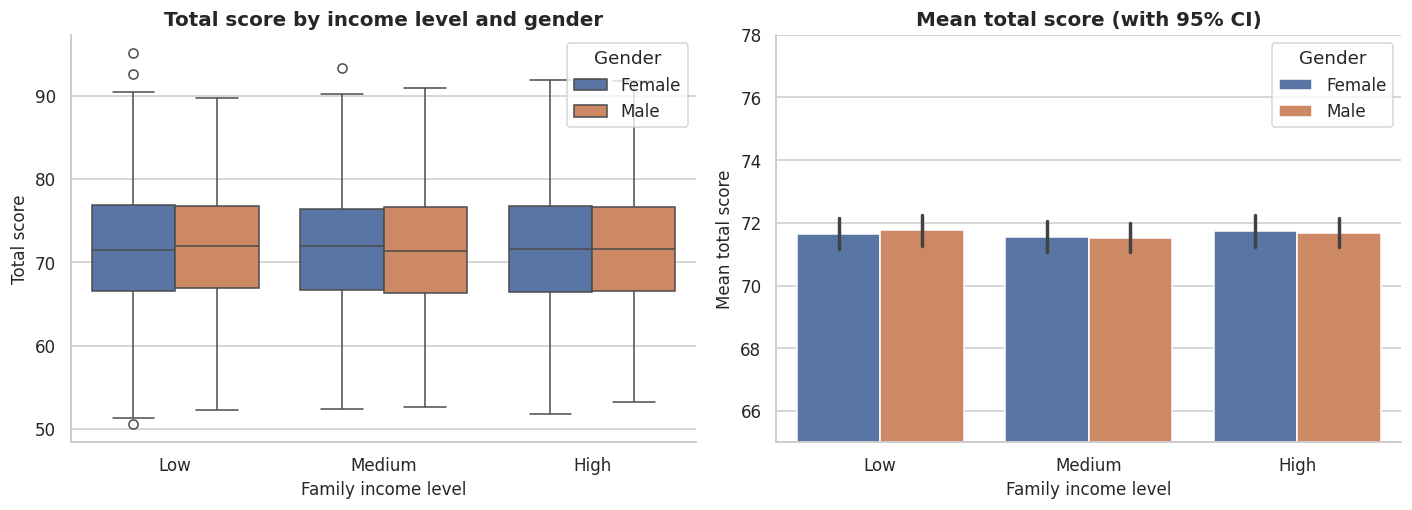

Gender,Female,Male,overall
Family_Income_Level,,,
Low,71.658,71.760,71.710
Medium,71.537,71.533,71.535
High,71.738,71.687,71.712


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.boxplot(data=df, x="Family_Income_Level", y="Total_Score", hue="Gender",
            order=inc_order, palette=["#4C72B0", "#DD8452"], ax=axes[0])
axes[0].set_title("Total score by income level and gender")
axes[0].set_xlabel("Family income level")
axes[0].set_ylabel("Total score")

sns.barplot(data=df, x="Family_Income_Level", y="Total_Score", hue="Gender",
            order=inc_order, palette=["#4C72B0", "#DD8452"], errorbar="ci", ax=axes[1])
axes[1].set_ylim(65, 78)
axes[1].set_title("Mean total score (with 95% CI)")
axes[1].set_xlabel("Family income level")
axes[1].set_ylabel("Mean total score")

plt.tight_layout()
plt.show()

pivot = df.pivot_table(index="Family_Income_Level", columns="Gender",
                       values="Total_Score", aggfunc="mean").reindex(inc_order).round(3)
pivot["overall"] = df.groupby("Family_Income_Level")["Total_Score"].mean().reindex(inc_order).round(3)
pivot

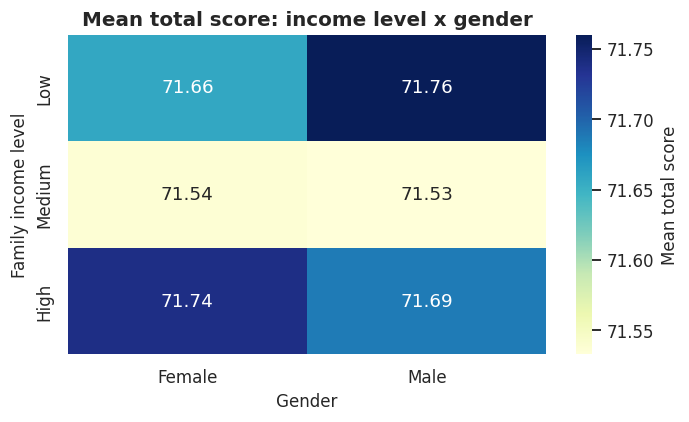

In [19]:
plt.figure(figsize=(6.5, 4))
sns.heatmap(pivot[["Female", "Male"]], annot=True, fmt=".2f", cmap="YlGnBu",
            cbar_kws={"label": "Mean total score"})
plt.title("Mean total score: income level x gender")
plt.ylabel("Family income level")
plt.tight_layout()
plt.show()

**Answer: no relationship, on either variable or in combination.**



## Task 13 — Average test score of students sleeping more than 6.5 hours

Students sleeping > 6.5 h : 2,487
Their average total score : 71.79
Whole-cohort average      : 71.65
Difference                : +0.14


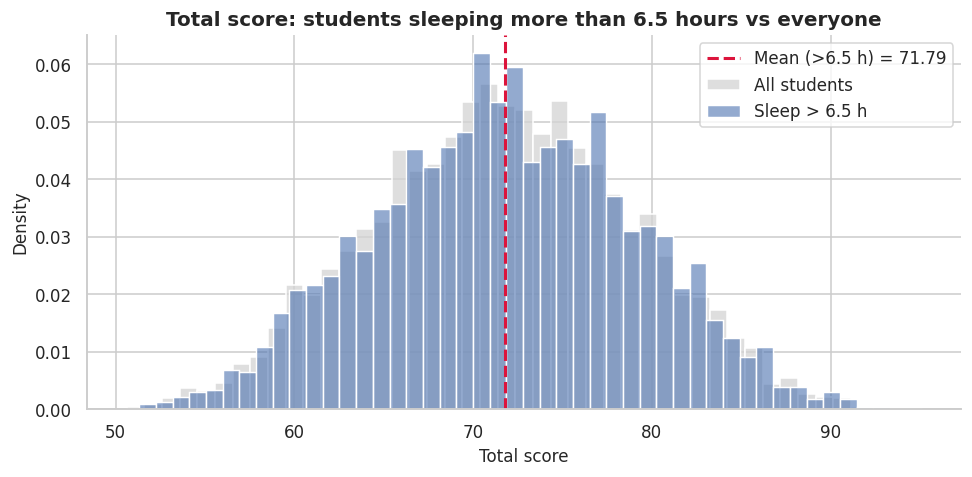

In [20]:
subset = df[df["Sleep_Hours_per_Night"] > 6.5]
avg = subset["Total_Score"].mean()

print(f"Students sleeping > 6.5 h : {len(subset):,}")
print(f"Their average total score : {avg:.2f}")
print(f"Whole-cohort average      : {df['Total_Score'].mean():.2f}")
print(f"Difference                : {avg - df['Total_Score'].mean():+.2f}")

plt.figure(figsize=(9, 4.5))
sns.histplot(df["Total_Score"], bins=45, color="lightgrey", label="All students", stat="density")
sns.histplot(subset["Total_Score"], bins=45, color="#4C72B0", alpha=0.6,
             label="Sleep > 6.5 h", stat="density")
plt.axvline(avg, color="crimson", ls="--", lw=2, label=f"Mean (>6.5 h) = {avg:.2f}")
plt.title("Total score: students sleeping more than 6.5 hours vs everyone")
plt.xlabel("Total score")
plt.legend()
plt.tight_layout()
plt.show()

**Answer: 71.79**

Based on 2,487 students who sleep more than 6.5 hours per night.


## Task 14 — How many students scored above 80?

Students scoring above 80 : 654  (13.1% of the cohort)


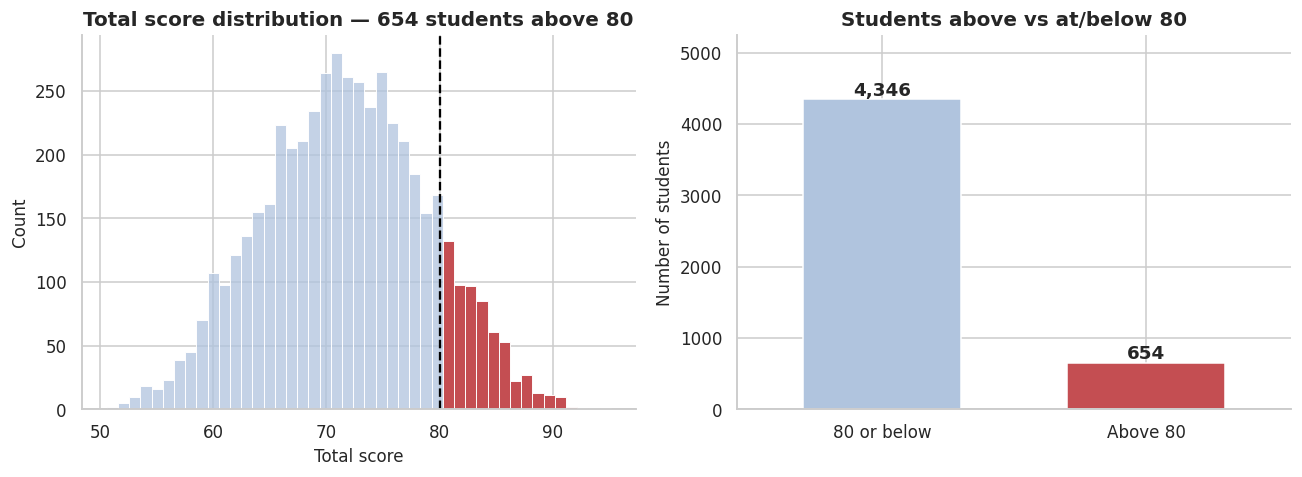

,students
Grade,
A,16
B,638


In [21]:
above = df[df["Total_Score"] > 80]
n_above = len(above)

print(f"Students scoring above 80 : {n_above:,}  ({n_above / len(df) * 100:.1f}% of the cohort)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(df["Total_Score"], bins=45, ax=axes[0], color="lightsteelblue")
for patch in axes[0].patches:
    if patch.get_x() >= 80:
        patch.set_facecolor("#C44E52")
axes[0].axvline(80, color="black", ls="--", lw=1.5)
axes[0].set_title(f"Total score distribution — {n_above:,} students above 80")
axes[0].set_xlabel("Total score")

split = pd.Series({"80 or below": len(df) - n_above, "Above 80": n_above})
ax = split.plot(kind="bar", ax=axes[1], color=["lightsteelblue", "#C44E52"], width=0.6)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontweight="bold")
axes[1].set_title("Students above vs at/below 80")
axes[1].set_ylabel("Number of students")
axes[1].set_ylim(0, len(df) * 1.05)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

above["Grade"].value_counts().reindex(["A", "B"]).to_frame("students")

**Answer: 654 students** scored above 80 — 13.1% of the cohort.

